### Top DISPACH2 location in your case:

In [ ]:
top='C:/cygwin64/home/codes/dispatch2/'

### Standard* setup

In [ ]:
import os
os.chdir(top+'tests/winds/python')

In [ ]:
import sys
sys.path.append(top+'utilities/python')

In [4]:
import dispatch as dis
import dispatch.select as dse
import dispatch.graphics as dgr

In [5]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


### Imaging velocity the central plane

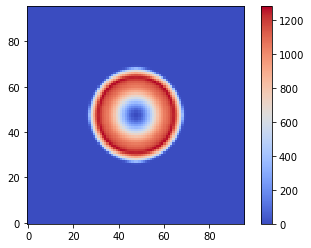

In [6]:
sn=dis.snapshot(2,run='96')
dgr.unigrid_plane(sn,iv='(ux**2+uy**2)**0.5')

### Plot of velocity through the center

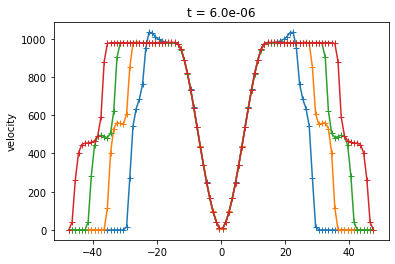

In [7]:
def pl1(io,run,iv='(ux**2+uy**2)**0.5',w=48):
    sn=dis.snapshot(io,run)
    f=dse.unigrid_plane(sn,iv=iv)
    n,n=f.shape
    m=n//2
    x=arange(n)-m+0.5
    plot(x[m-w:m+w],f[m-w:m+w,m],'-+'), title('t = {:.1e}'.format(sn.time));
    ylabel('velocity')
    #print('{:2d}   {:.3e}'.format(io,sn.time))
for io in range(3,7):
    pl1(io,'96')

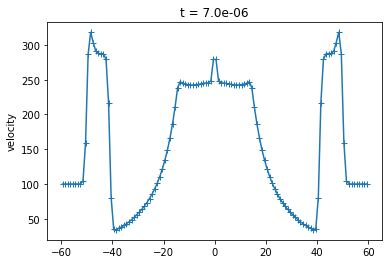

In [8]:
pl1(7,'224','d',60)

### Imaging velocity and density, zoomed in

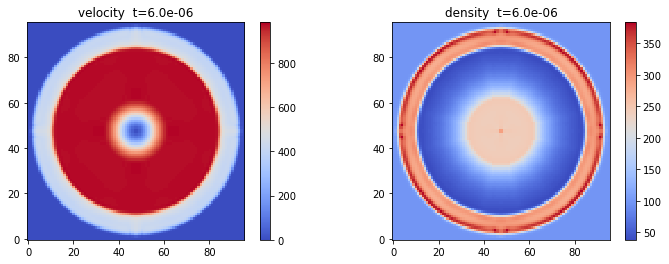

In [9]:
def im2(io=3,run='96',w=48):
    sn=dis.snapshot(io,run)
    c=sn.cartesian.dims[0]*sn.patch.n[0]/2-0.5
    figure(2,figsize=(12,4))
    iv='(ux**2+uy**2)**0.5'
    subplot(1,2,1); dgr.unigrid_plane(sn,iv=iv)
    title('velocity  t={:.1e}'.format(sn.time))
    xlim(c-w,c+w); ylim(c-w,c+w)
    iv='d'
    subplot(1,2,2); dgr.unigrid_plane(sn,iv=iv)
    xlim(c-w,c+w); ylim(c-w,c+w)
    title('density  t={:.1e}'.format(sn.time));
im2(6)

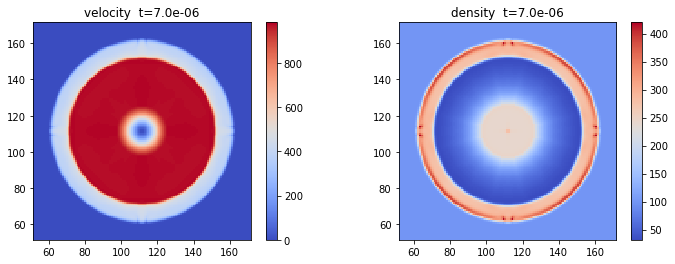

In [10]:
im2(7,'224',60)

### Imaging velocity, density and pressure

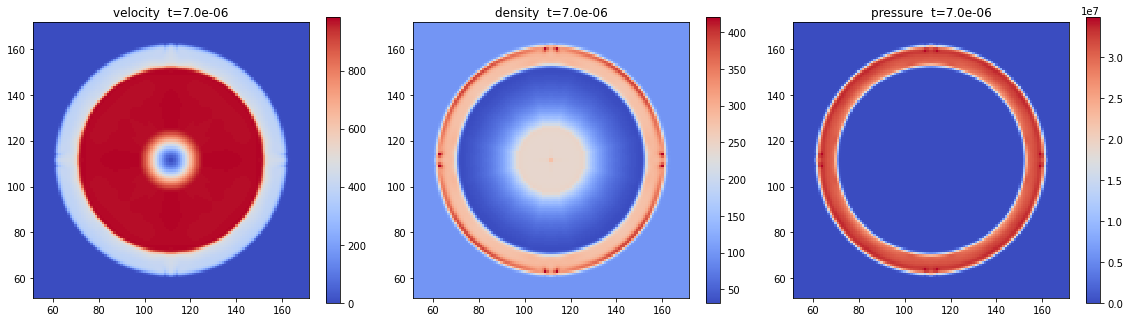

In [11]:
def im3(io=2,run='224',w=50):
    sn=dis.snapshot(io,run)
    c=sn.cartesian.dims[0]*sn.patch.n[0]/2-0.5
    figure(3,figsize=(16,4.5))
    def im1(i,iv,s):
        subplot(1,3,i); dgr.unigrid_plane(sn,iv=iv)
        title('{}  t={:.1e}'.format(s,sn.time))
        xlim(c-w,c+w); ylim(c-w,c+w)
    im1(1,'(ux**2+uy**2)**0.5','velocity')
    im1(2,'d','density')
    im1(3,'eth','pressure')
    tight_layout()
im3(7,w=60)

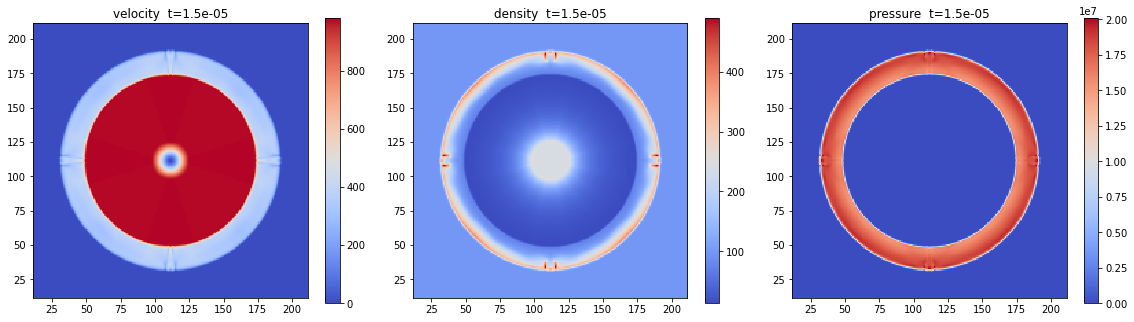

In [12]:
im3(15,w=100)

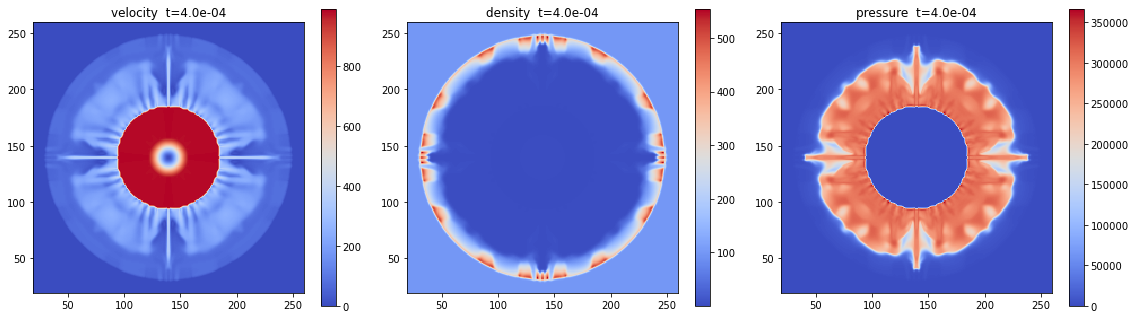

In [78]:
im3(40,'280',w=120)